In [1]:
import pickle

In [2]:
with open('ner_train.pkl', 'rb') as f:
  corpus_train = pickle.load(f)

with open('ner_test.pkl', 'rb') as f:
  corpus_test = pickle.load(f)

In [3]:
train_inputs = []
train_targets = []

for sentence_tag_pairs in corpus_train:
    tokens = []
    target = []

    for token, tag in sentence_tag_pairs:
        tokens.append(token)
        target.append(tag)

    train_inputs.append(tokens)
    train_targets.append(target)

In [4]:
test_inputs = []
test_targets = []

for sentence_tag_pairs in corpus_test:
    tokens = []
    target = []

    for token, tag in sentence_tag_pairs:
        tokens.append(token)
        target.append(tag)

    test_inputs.append(tokens)
    test_targets.append(target)

In [5]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Dense, Input, Bidirectional
from tensorflow.keras.layers import LSTM, GRU, SimpleRNN, Embedding
from tensorflow.keras.models import Model
from tensorflow.keras.losses import SparseCategoricalCrossentropy

In [6]:
# Convert sentences to sequences

MAX_VOCAB_SIZE = None

# capitalization might be useful - test it
should_lowercase = False

word_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    lower=should_lowercase,
    oov_token='UNK',
)

# otherwise unknown tokens will be removed and len(input) != len(target)
# input words and target words will not be aligned!

# it's ok to "fit" on the whole corpus - it just means some embeddings
# won't be trained
# this is because for the test set, any unknown tokens will be removed
# which will change the length of the input (***CHECK)

word_tokenizer.fit_on_texts(train_inputs)

train_inputs_int = word_tokenizer.texts_to_sequences(train_inputs)
test_inputs_int = word_tokenizer.texts_to_sequences(test_inputs)

In [7]:
# get word -> integer mapping
word2idx = word_tokenizer.word_index
V = len(word2idx)

print('Found %s unique tokens.' % V)

Found 23299 unique tokens.


In [8]:
# https://stackoverflow.com/questions/11264684/flatten-list-of-lists
def flatten(list_of_lists):
    flattened = [val for sublist in list_of_lists for val in sublist]
    return flattened

In [9]:
all_train_targets = set(flatten(train_targets))
all_train_targets

{'B-LOC', 'B-MISC', 'B-ORG', 'B-PER', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O'}

In [10]:
all_test_targets = set(flatten(test_targets))
all_test_targets

{'B-LOC', 'B-MISC', 'B-ORG', 'B-PER', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O'}

In [11]:
all_train_targets == all_test_targets

True

In [12]:
tag_tokenizer = Tokenizer()
tag_tokenizer.fit_on_texts(train_targets)

train_targets_int = tag_tokenizer.texts_to_sequences(train_targets)
test_targets_int = tag_tokenizer.texts_to_sequences(test_targets)

# save for later
train_targets_int_unpadded = train_targets_int
test_targets_int_unpadded = test_targets_int

In [13]:
maxlen_train = max(len(sent) for sent in train_inputs)
maxlen_test = max(len(sent) for sent in test_inputs)

T = max((maxlen_train, maxlen_test))

In [14]:
train_inputs_int = pad_sequences(train_inputs_int, maxlen=T)
print('Shape of data train tensor:', train_inputs_int.shape)

Shape of data train tensor: (12733, 113)


In [15]:
test_inputs_int = pad_sequences(test_inputs_int, maxlen=T)
print('Shape of data test tensor:', test_inputs_int.shape)

Shape of data test tensor: (2970, 113)


In [16]:
train_targets_int = pad_sequences(train_targets_int, maxlen=T)
print('Shape of train targets tensor:', train_targets_int.shape)

Shape of train targets tensor: (12733, 113)


In [17]:
test_targets_int = pad_sequences(test_targets_int, maxlen=T)
print('Shape of test targets tensor:', test_targets_int.shape)

Shape of test targets tensor: (2970, 113)


In [18]:
# number of classes
K = len(tag_tokenizer.word_index) + 1
K

10

In [19]:
# Create the model

# We get to choose embedding dimensionality
D = 32

i = Input(shape=(T,))

# mask_zero=True way slower on GPU than CPU!
x = Embedding(V + 1, D, mask_zero=True)(i)
x = Bidirectional(LSTM(32, return_sequences=True))(x)
x = Dense(int(K))(x)

model = Model(i, x)

In [20]:
# Compile and fit
model.compile(
    loss=SparseCategoricalCrossentropy(from_logits=True),
    optimizer='adam',
    metrics=['accuracy']
)

# NOTE: you "could" speed this up by creating a custom loss, since Tensorflow's
# implementation of mask_zero currently sucks, but it's sufficiently advanced
# to be outside the scope of this course
# In my experiments, CPU is faster than GPU in all cases, and CPU for custom
# loss is faster than CPU for mask_zero

# > 300-400s per epoch on CPU
# > 30 MINUTES per epoch on GPU

print('Training model...')
r = model.fit(
    train_inputs_int,
    train_targets_int,
    epochs=5,
    validation_data=(test_inputs_int, test_targets_int)
)

Training model...
Epoch 1/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 36s 77ms/step - accuracy: 0.8400 - loss: 0.6948 - val_accuracy: 0.8653 - val_loss: 0.4736
Epoch 2/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - accuracy: 0.9075 - loss: 0.2903 - val_accuracy: 0.9138 - val_loss: 0.3161
Epoch 3/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 30s 75ms/step - accuracy: 0.9524 - loss: 0.1650 - val_accuracy: 0.9264 - val_loss: 0.2516
Epoch 4/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 29s 74ms/step - accuracy: 0.9783 - loss: 0.0876 - val_accuracy: 0.9316 - val_loss: 0.2225
Epoch 5/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 30s 74ms/step - accuracy: 0.9884 - loss: 0.0508 - val_accuracy: 0.9386 - val_loss: 0.2071


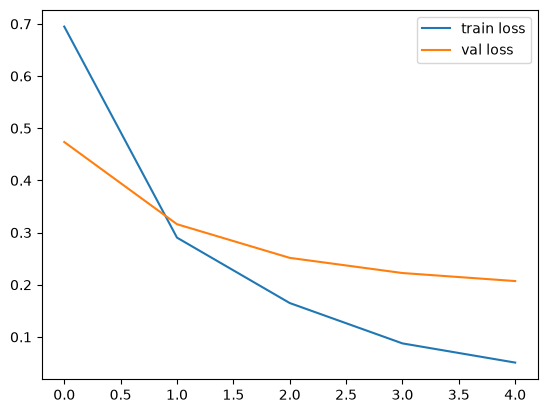

In [21]:
# Plot loss per iteration
plt.plot(r.history['loss'], label='train loss')
plt.plot(r.history['val_loss'], label='val loss')
plt.legend();

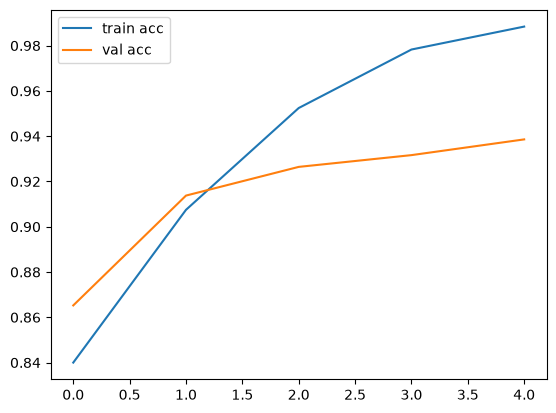

In [22]:
# Plot accuracy per iteration
plt.plot(r.history['accuracy'], label='train acc')
plt.plot(r.history['val_accuracy'], label='val acc')
plt.legend();

In [23]:
# True model accuracy - above includes padding

# first get length of each sequence
train_lengths = []
for sentence in train_inputs:
    train_lengths.append(len(sentence))

test_lengths = []
for sentence in test_inputs:
    test_lengths.append(len(sentence))

In [24]:
train_probs = model.predict(train_inputs_int)  # N x T x K

train_predictions = []
for probs, length in zip(train_probs, train_lengths):
    # probs is T x K
    probs_ = probs[-length:]
    preds = np.argmax(probs_, axis=1)
    train_predictions.append(preds)
flat_train_predictions = flatten(train_predictions)
flat_train_targets = flatten(train_targets_int_unpadded)

398/398 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step


In [25]:
test_probs = model.predict(test_inputs_int)  # N x T x K

test_predictions = []
for probs, length in zip(test_probs, test_lengths):
    # probs is T x K
    probs_ = probs[-length:]
    preds = np.argmax(probs_, axis=1)
    test_predictions.append(preds)

# flatten
flat_test_predictions = flatten(test_predictions)
flat_test_targets = flatten(test_targets_int_unpadded)

93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


In [26]:
from sklearn.metrics import accuracy_score, f1_score

print(
    "Train acc:",
    accuracy_score(flat_train_targets, flat_train_predictions)
)

print(
    "Test acc:",
    accuracy_score(flat_test_targets, flat_test_predictions)
)

print(
    "Train f1:",
    f1_score(
        flat_train_targets,
        flat_train_predictions,
        average='macro'
    )
)

print(
    "Test f1:",
    f1_score(
        flat_test_targets,
        flat_test_predictions,
        average='macro'
    )
)

Train acc: 0.9926783442023223
Test acc: 0.9385835448767145
Train f1: 0.9452616561589432
Test f1: 0.7674016440500361


In [27]:
### Baseline model: map word to tag
from collections import Counter

# https://stackoverflow.com/questions/1518522/find-the-most-common-element-in-a-list
def most_common(lst):
    data = Counter(lst)
    return data.most_common(1)[0][0]

In [28]:
token2tags = {k: [] for k, v in word2idx.items()}

# remove UNK token
del token2tags['UNK']

for tokens, tags in zip(train_inputs, train_targets):
    for token, tag in zip(tokens, tags):
        if should_lowercase:
            token = token.lower()

        if token in token2tags:
            token2tags[token].append(tag)

token2tag = {
    k: most_common(v)
    for k, v in token2tags.items()
}

In [29]:
# compute accuracy

train_predictions = []
for sentence in train_inputs:
    predictions = []

    for token in sentence:
        if should_lowercase:
            token = token.lower()

        predicted_tag = token2tag[token]
        predictions.append(predicted_tag)

    train_predictions.append(predictions)

flat_train_predictions = flatten(train_predictions)
flat_train_targets = flatten(train_targets)

In [30]:
test_predictions = []
for sentence in test_inputs:
    predictions = []

    for token in sentence:
        predicted_tag = token2tag.get(token, 'INCORRECT')
        predictions.append(predicted_tag)

    test_predictions.append(predictions)

flat_test_predictions = flatten(test_predictions)
flat_test_targets = flatten(test_targets)

In [31]:
print(
    "Train acc:",
    accuracy_score(flat_train_targets, flat_train_predictions)
)

print(
    "Test acc:",
    accuracy_score(flat_test_targets, flat_test_predictions)
)

print(
    "Train f1:",
    f1_score(
        flat_train_targets,
        flat_train_predictions,
        average='macro'
    )
)

print(
    "Test f1:",
    f1_score(
        flat_test_targets,
        flat_test_predictions,
        average='macro'
    )
)

Train acc: 0.974769365357086
Test acc: 0.8881673455733318
Train f1: 0.8549353965547479
Test f1: 0.6381158268902334
